# Módulo 2 — Práctica: inspección de NetCDF y GRIB2

Ejercicios 1 y 2 de la práctica del Día 3 (ver [`README.md`](../README.md)).
Cada ejercicio tiene un **📘 ejemplo resuelto**, un **✍️ tu turno**
(completa las líneas marcadas con `✍️`) y una celda **✔️ comprobar**.
Trabaja en tu copia `02_practica_inspeccion_netcdf_grib_mio.ipynb`.

> **Sobre los datos de este módulo.** Los **📘 ejemplos resueltos** usan
> archivos **sintéticos**: los genera `synth_data.py` con las mismas
> convenciones que un ERA5 o un GFS real (CF, latitud descendente, nombres de
> variable). Así sabemos exactamente qué contienen y el resultado es igual en
> todas las computadoras. Los **✍️ tu turno** usan un archivo **real**: ERA5
> sobre el Perú del 13 de diciembre de 2024
> (`data/era_muestra/era5_peru_20241213.nc`), descargado con `cdsapi` igual
> que en el Módulo 3.

## Ejercicio 1 — Inspección de un NetCDF "tipo ERA5" (40 min)

### 📘 Ejemplo resuelto

Se genera un dataset **sintético** con la misma convención de ERA5 real
(mismo generador usado en `01_teoria_demos.ipynb`) y se guarda como NetCDF,
para inspeccionarlo como si acabara de descargarse.

In [1]:
import numpy as np
from synth_data import era5_like_dataset

ds = era5_like_dataset(periods=7 * 24, seed=5)
ds.to_netcdf("ejercicio1_era5_like.nc")

import xarray as xr
ds = xr.open_dataset("ejercicio1_era5_like.nc")
ds

<xarray.Dataset> Size: 710kB
Dimensions:    (time: 168, latitude: 31, longitude: 17)
Coordinates:
  * time       (time) datetime64[ns] 1kB 2026-01-15 ... 2026-01-21T23:00:00
  * latitude   (latitude) float64 248B 10.0 9.0 8.0 7.0 ... -18.0 -19.0 -20.0
  * longitude  (longitude) float64 136B -82.0 -81.0 -80.0 ... -68.0 -67.0 -66.0
Data variables:
    t2m        (time, latitude, longitude) float32 354kB ...
    msl        (time, latitude, longitude) float32 354kB ...
Attributes:
    Conventions:  CF-1.7
    institution:  Datos sinteticos (curso Python-WRF) - NO son ERA5 real
    history:      Generado localmente sin conexion a Copernicus CDS

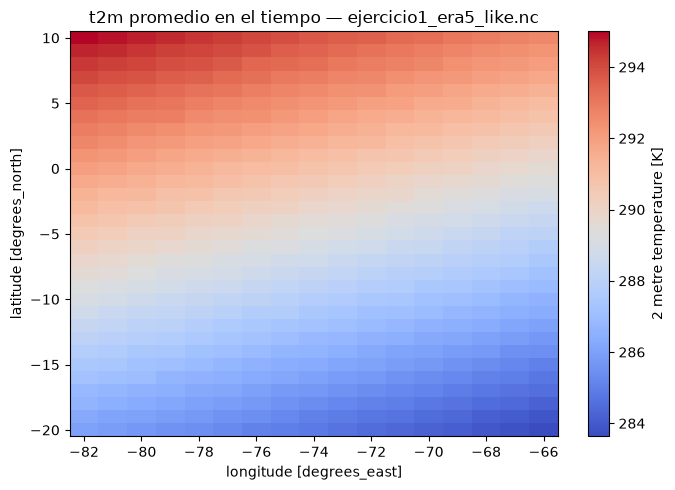

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
ds["t2m"].mean(dim="time").plot(ax=ax, cmap="coolwarm")
ax.set_title("t2m promedio en el tiempo — ejercicio1_era5_like.nc")
fig.tight_layout()
plt.show()

**Preguntas a responder (con código, no de memoria):**

In [3]:
# 1. ¿En qué unidades está la temperatura?
print("Unidades de t2m:", ds["t2m"].attrs["units"])

# 2. ¿La latitud es ascendente o descendente?
lat = ds["latitude"].values
orden = "descendente" if lat[0] > lat[-1] else "ascendente"
print(f"Orden de latitud: {orden} (primeros valores: {lat[:3]})")

# 3. ¿Qué convención declara el atributo global 'Conventions'?
print("Conventions:", ds.attrs["Conventions"])

# 4. Rango temporal cubierto
print("Rango temporal:", str(ds.time.min().values), "a", str(ds.time.max().values))

Unidades de t2m: K
Orden de latitud: descendente (primeros valores: [10.  9.  8.])
Conventions: CF-1.7
Rango temporal: 2026-01-15T00:00:00.000000000 a 2026-01-21T23:00:00.000000000


**Refuerzo — la misma inspección, sobre OTRA variable del mismo archivo.**
`ejercicio1_era5_like.nc` no trae solo `t2m`: también trae `msl` (presión a
nivel del mar). Repetir el mismo tipo de preguntas sobre `msl` sirve para
comprobar que la lógica de inspección se generalizó de verdad (no se
memorizaron las respuestas de `t2m`) — y de paso expone un caso real
frecuente: las unidades de presión en ERA5 son **pascales (Pa)**, no
hectopascales (hPa), que es la unidad con la que casi siempre se habla de
presión atmosférica en la práctica meteorológica.

In [4]:
# Mismas preguntas, ahora sobre 'msl'
print("Unidades de msl:", ds["msl"].attrs["units"])
print("long_name:", ds["msl"].attrs["long_name"])
print("standard_name:", ds["msl"].attrs["standard_name"])
print()

msl_pa = ds["msl"]
msl_hpa = msl_pa / 100  # Pa -> hPa, la conversion que casi siempre hay que hacer

print(f"Promedio en Pa:  {float(msl_pa.mean()):.1f}")
print(f"Promedio en hPa: {float(msl_hpa.mean()):.1f}  <- este es el numero que reconocerian de un mapa sinoptico")
print()
print("Si alguien olvida dividir entre 100, un mapa de 'msl' en Pa muestra",
      "valores como 101300 en vez de 1013 -- no es un error de datos, es",
      "una unidad sin convertir. Siempre revisar 'units' antes de graficar",
      "o comparar contra otra fuente.")

Unidades de msl: Pa
long_name: Mean sea level pressure
standard_name: air_pressure_at_mean_sea_level

Promedio en Pa:  101300.6
Promedio en hPa: 1013.0  <- este es el numero que reconocerian de un mapa sinoptico

Si alguien olvida dividir entre 100, un mapa de 'msl' en Pa muestra valores como 101300 en vez de 1013 -- no es un error de datos, es una unidad sin convertir. Siempre revisar 'units' antes de graficar o comparar contra otra fuente.


### ✍️ Tu turno — Ejercicio 1, con un ERA5 real

Abre el archivo real `data/era_muestra/era5_peru_20241213.nc` y responde
**con código** (no a ojo), guardando cada respuesta en su variable:

1. `unidades_t2m`: las unidades de `t2m`;
2. `lat_descendente`: `True` o `False`;
3. `nombre_tiempo`: el nombre de la coordenada de tiempo. Ojo: no es igual
   al del ejemplo sintético. Mira `list(era5.coords)`;
4. `unidades_tp`: las unidades de la precipitación total `tp`. ¿Son mm?

In [5]:
# ✍️ TU TURNO
era5 = xr.open_dataset("../../../data/era_muestra/era5_peru_20241213.nc")

unidades_t2m = None                   # ✍️
lat_descendente = None                # ✍️
nombre_tiempo = None                  # ✍️
unidades_tp = None                    # ✍️

In [6]:
# ✔️ COMPROBAR
respuestas = [unidades_t2m, lat_descendente, nombre_tiempo, unidades_tp]
if all(r is None for r in respuestas):
    print("⏳ Todavía no completas la celda anterior.")
else:
    print("✅ 1." if unidades_t2m == "K" else "❌ 1. Lee el atributo \"units\" de t2m.")
    print("✅ 2." if lat_descendente is True else "❌ 2. Compara el primer y el último valor de la latitud.")
    print("✅ 3." if nombre_tiempo == "valid_time" else "❌ 3. Busca en list(era5.coords) la coordenada con fechas.")
    print("✅ 4. Son metros: hay que multiplicar por 1000 para tener mm." if unidades_tp == "m"
          else "❌ 4. Lee el atributo \"units\" de tp.")

⏳ Todavía no completas la celda anterior.


## Ejercicio 2 — Apertura de un GRIB2 "tipo GFS" con cfgrib (35 min)

### 📘 Ejemplo resuelto

Se genera un archivo GRIB2 **sintético** con `eccodes` (offline, sin
depender de internet) y se abre con `cfgrib`, comparando su estructura
contra el NetCDF del Ejercicio 1.

In [7]:
from synth_data import escribir_grib2_sintetico

escribir_grib2_sintetico(
    "ejercicio2_gfs_like.grib2",
    ni=17, nj=31,
    lat_first=10.0, lat_last=-20.0,
    lon_first=-82.0, lon_last=-66.0,
    seed=9,
)

ds_grib = xr.open_dataset("ejercicio2_gfs_like.grib2", engine="cfgrib")
ds_grib

<xarray.Dataset> Size: 3kB
Dimensions:            (latitude: 31, longitude: 17)
Coordinates:
  * latitude           (latitude) float64 248B 10.0 9.0 8.0 ... -19.0 -20.0
  * longitude          (longitude) float64 136B 278.0 279.0 ... 293.0 294.0
    time               datetime64[ns] 8B ...
    step               timedelta64[ns] 8B ...
    heightAboveGround  float64 8B ...
    valid_time         datetime64[ns] 8B ...
Data variables:
    t2m                (latitude, longitude) float32 2kB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-24T03:26 GRIB to CDM+CF via cfgrib-0.9.1...

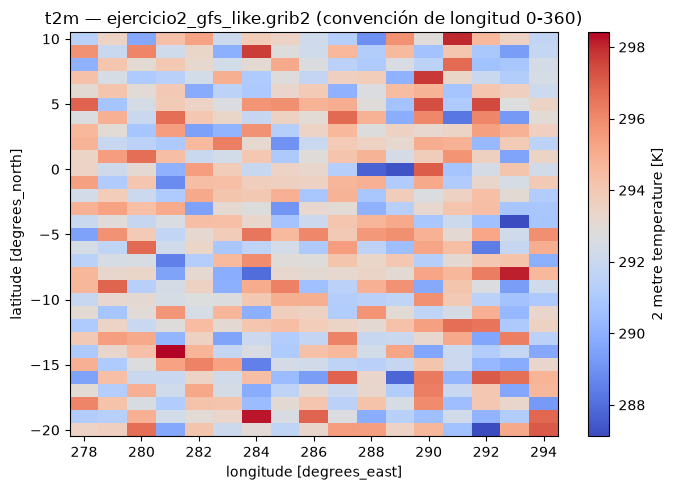

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ds_grib["t2m"].plot(ax=ax, cmap="coolwarm")
ax.set_title("t2m — ejercicio2_gfs_like.grib2 (convención de longitud 0-360)")
fig.tight_layout()
plt.show()

In [9]:
print("=== Comparación de estructura ===")
print(f"{'':20s}{'NetCDF (ERA5-like)':25s}{'GRIB2 (GFS-like)'}")
print(f"{'Variable temp.':20s}{'t2m':25s}{list(ds_grib.data_vars)[0]}")
print(f"{'Dim. lat':20s}{ds.sizes['latitude']:<25}{ds_grib.sizes['latitude']}")
print(f"{'Dim. lon':20s}{ds.sizes['longitude']:<25}{ds_grib.sizes['longitude']}")
print(f"{'Rango lon crudo':20s}{f'{float(ds.longitude.min())} a {float(ds.longitude.max())}':25s}"
      f"{float(ds_grib.longitude.min())} a {float(ds_grib.longitude.max())}")
print()
print("Nota: en este ejercicio ambas fuentes usan 't2m' porque generamos el",
      "GRIB2 con shortName='2t' -> cfgrib lo decodifica como 't2m'. En la",
      "práctica real, distintos centros meteorológicos SÍ pueden usar",
      "convenciones de nombre distintas para la misma variable física, por",
      "lo que siempre conviene verificar 'long_name'/'standard_name', no",
      "solo el nombre corto de la variable.")

=== Comparación de estructura ===
                    NetCDF (ERA5-like)       GRIB2 (GFS-like)
Variable temp.      t2m                      t2m
Dim. lat            31                       31
Dim. lon            17                       17
Rango lon crudo     -82.0 a -66.0            278.0 a 294.0

Nota: en este ejercicio ambas fuentes usan 't2m' porque generamos el GRIB2 con shortName='2t' -> cfgrib lo decodifica como 't2m'. En la práctica real, distintos centros meteorológicos SÍ pueden usar convenciones de nombre distintas para la misma variable física, por lo que siempre conviene verificar 'long_name'/'standard_name', no solo el nombre corto de la variable.


### ✍️ Tu turno — Ejercicio 2

El GRIB2 trae la longitud en convención 0°–360°. Para cruzarlo con el ERA5,
que usa −180°/180°:

1. crea `ds_grib_180`: una copia de `ds_grib` con la longitud convertida a
   −180/180. Pista: la fórmula está en la teoría (Sección 3), y
   `ds_grib.assign_coords(longitude=...)` reemplaza una coordenada;
2. guarda en `t2m_lima` el valor de `t2m` en el punto de grilla más cercano
   a Lima (−12.05, −77.05), seleccionando **en −180/180**.

In [10]:
# ✍️ TU TURNO
ds_grib_180 = None                    # ✍️ 1.
t2m_lima = None                       # ✍️ 2. .sel(..., method="nearest")

In [11]:
# ✔️ COMPROBAR
if ds_grib_180 is None or t2m_lima is None:
    print("⏳ Todavía no completas la celda anterior.")
elif float(ds_grib_180.longitude.min()) >= 0:
    print("❌ 1. La longitud sigue en 0-360:", ds_grib_180.longitude.values[:3])
else:
    referencia = ds_grib["t2m"].sel(latitude=-12.05, longitude=-77.05 % 360, method="nearest")
    if np.isclose(float(t2m_lima), float(referencia)):
        print(f"✅ ¡Correcto! t2m en el nodo más cercano a Lima: {float(t2m_lima):.2f} K")
    else:
        print("❌ 2. Valor distinto al esperado: ¿usaste method=\"nearest\" y longitud -77.05?")

⏳ Todavía no completas la celda anterior.


## Cierre

Entregable parcial: tu copia de este notebook con los ✔️ en `✅`, y los
archivos `ejercicio1_era5_like.nc` y `ejercicio2_gfs_like.grib2` generados.
Continuar con
[`03_practica_recorte_dominio.ipynb`](03_practica_recorte_dominio.ipynb).